In [15]:
import pandas as pd
import numpy as np
df = pd.read_csv("/content/insurance.csv")
print(df.head())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [16]:
print(df.shape)

(1338, 7)


In [17]:
print(df.columns.tolist())

['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


In [18]:
print(df.dtypes)

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


In [19]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None


In [20]:
print(df.describe())

               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000    53.130000     5.000000  63770.428010


In [21]:
# 1. Missing values
print("Missing values:")
print(df.isnull().sum())

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [22]:
# 2. Duplicate
print("\nDuplicate rows:", df.duplicated().sum())
# Remove duplicates
df_clean = df.drop_duplicates()
print("Shape after removing duplicates:", df_clean.shape)

# 3. Data types before encoding
print("\nBefore Encoding:")
print(df_clean.dtypes)



Duplicate rows: 1
Shape after removing duplicates: (1337, 7)

Before Encoding:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


In [23]:
# 4. Encode categorical variables
from sklearn.preprocessing import LabelEncoder

df_encoded = df_clean.copy()
le = LabelEncoder()

df_encoded['sex'] = le.fit_transform(df_encoded['sex'])
df_encoded['smoker'] = le.fit_transform(df_encoded['smoker'])
df_encoded['region'] = le.fit_transform(df_encoded['region'])

print("\nAfter Encoding:")
print(df_encoded.head())
print(df_encoded.dtypes)

# 5. Final dataset
print("\nFinal Dataset Shape:", df_encoded.shape)
print("Final Dataset:")
print(df_encoded.head())



After Encoding:
   age  sex     bmi  children  smoker  region      charges
0   19    0  27.900         0       1       3  16884.92400
1   18    1  33.770         1       0       2   1725.55230
2   28    1  33.000         3       0       2   4449.46200
3   33    1  22.705         0       0       1  21984.47061
4   32    1  28.880         0       0       1   3866.85520
age           int64
sex           int64
bmi         float64
children      int64
smoker        int64
region        int64
charges     float64
dtype: object

Final Dataset Shape: (1337, 7)
Final Dataset:
   age  sex     bmi  children  smoker  region      charges
0   19    0  27.900         0       1       3  16884.92400
1   18    1  33.770         1       0       2   1725.55230
2   28    1  33.000         3       0       2   4449.46200
3   33    1  22.705         0       0       1  21984.47061
4   32    1  28.880         0       0       1   3866.85520


In [24]:
# Save final cleaned file
df_encoded.to_csv("cleaned_insurance.csv", index=False)
print("\n✅ cleaned_insurance.csv saved!")


✅ cleaned_insurance.csv saved!


               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000    53.130000     5.000000  63770.428010
smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64
               age       bmi  children   charges
age       1.000000  0.109272  0.042469  0.299008
bmi       0.109272  1.000000  0.012759  0.198341
children  0.042469  0.012759  1.000000  0.067998
charges   0.299008  0.198341  0.067998  1.000000


/tmp/ipykernel_3735/1008060824.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([df[df.smoker=='no'].charges, df[df.smoker=='yes'].charges], labels=['no','yes'])


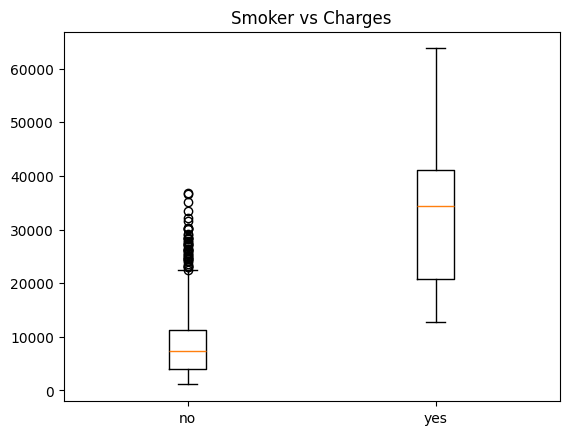

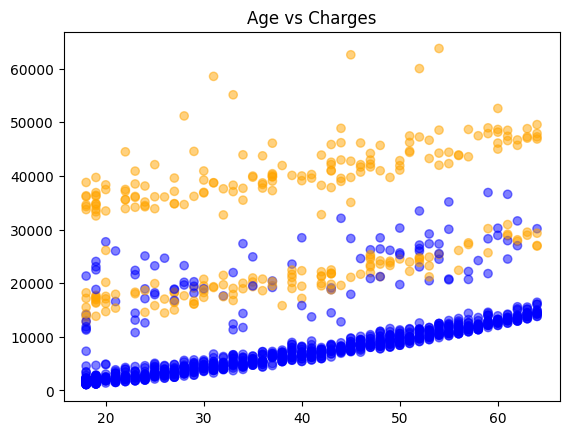

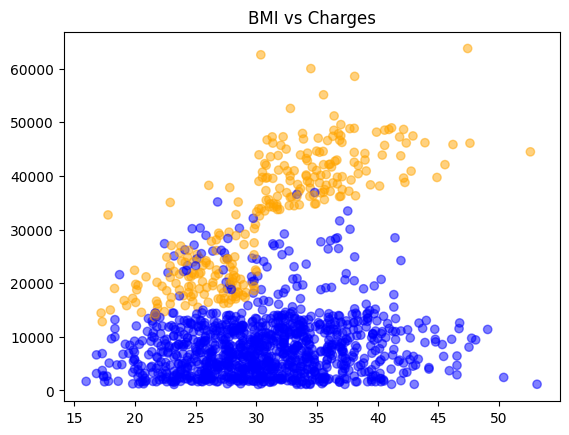

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# Load your cleaned dataset
df = pd.read_csv("/content/insurance.csv")

# 1. Statistical Summary
print(df.describe())
print(df.groupby('smoker')['charges'].mean())

# 2. Correlation
print(df[['age','bmi','children','charges']].corr())

# 3. Visualizations
plt.figure()
plt.boxplot([df[df.smoker=='no'].charges, df[df.smoker=='yes'].charges], labels=['no','yes'])
plt.title('Smoker vs Charges')
plt.savefig('smoker_boxplot.png')

plt.figure()
plt.scatter(df['age'], df['charges'], c=df['smoker'].map({'yes':'orange','no':'blue'}), alpha=0.5)
plt.title('Age vs Charges')
plt.savefig('age_charges.png')

# Same for BMI
plt.figure()
plt.scatter(df['bmi'], df['charges'], c=df['smoker'].map({'yes':'orange','no':'blue'}), alpha=0.5)
plt.title('BMI vs Charges')
plt.savefig('bmi_charges.png')

In [26]:
# Day 20 - Select and Train ML Model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

# 1. Reload cleaned file
df = pd.read_csv("cleaned_insurance.csv")
print("Cleaned file loaded:", df.shape)

# 2. X and y preparation
X = df.drop('charges', axis=1)
y = df['charges']
print("\n--- X and y Preparation ---")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"X columns: {list(X.columns)}")
print(X.head(2))

# 3. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("\n--- Train/Test Split ---")
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

# 4. Model Training Code
print("\n--- Model Training Code ---")
model = LinearRegression()
print("Code: model = LinearRegression()")
print("Code: model.fit(X_train, y_train)")

# 5. Successful Model Training
model.fit(X_train, y_train)
print("\n--- Model Trained Successfully! ---")
print(f"Intercept: {model.intercept_}")
print(f"Coefficients: {model.coef_}")

# 6. Sample Predictions
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n--- Evaluation ---")
print(f"MSE: {mse}")
print(f"R2 Score: {r2}")

print("\n--- Sample Predictions (5 examples) ---")
for i in range(5):
    print(f"Actual: ${y_test.iloc[i]:.2f} | Predicted: ${y_pred[i]:.2f}")

Cleaned file loaded: (1337, 7)

--- X and y Preparation ---
X shape: (1337, 6)
y shape: (1337,)
X columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
   age  sex    bmi  children  smoker  region
0   19    0  27.90         0       1       3
1   18    1  33.77         1       0       2

--- Train/Test Split ---
X_train: (1069, 6), X_test: (268, 6)
y_train: (1069,), y_test: (268,)

--- Model Training Code ---
Code: model = LinearRegression()
Code: model.fit(X_train, y_train)

--- Model Trained Successfully! ---
Intercept: -11047.686556720197
Coefficients: [  248.76407134   -99.69539417   312.60904469   534.12087654
 23052.15275173  -237.62514748]

--- Evaluation ---
MSE: 35493102.61165051
R2 Score: 0.8068466322629112

--- Sample Predictions (5 examples) ---
Actual: $8688.86 | Predicted: $8080.45
Actual: $5708.87 | Predicted: $5592.87
Actual: $11436.74 | Predicted: $14378.30
Actual: $38746.36 | Predicted: $31731.82
Actual: $4463.21 | Predicted: $9158.36


===== PROJECT PHASE 6 - EVALUATION =====
MAE: 4182.35
MSE: 35493102.61
RMSE: 5957.61
R2 Score: 0.8068

--- Actual vs Predicted (5 examples) ---
Actual: $8688.86 | Predicted: $8080.45
Actual: $5708.87 | Predicted: $5592.87
Actual: $11436.74 | Predicted: $14378.30
Actual: $38746.36 | Predicted: $31731.82
Actual: $4463.21 | Predicted: $9158.36


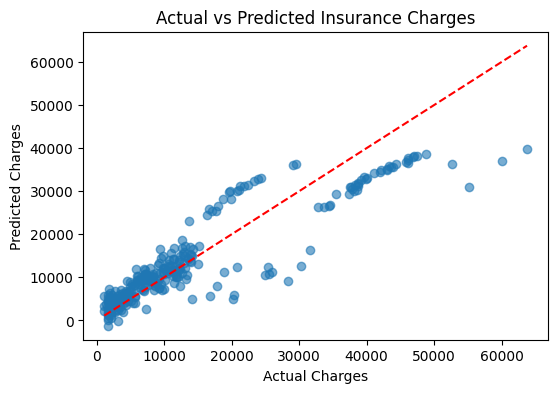

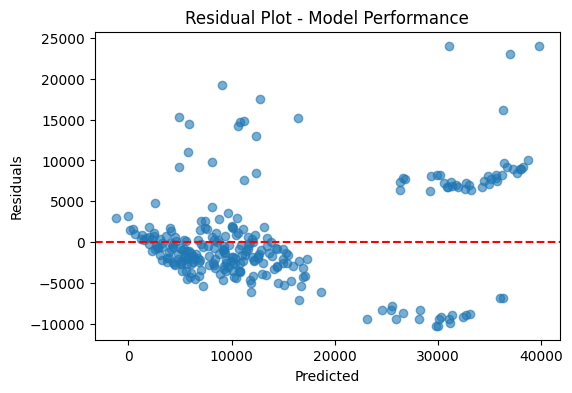

In [27]:
# FINAL EVALUATION
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt


mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("===== PROJECT PHASE 6 - EVALUATION =====")
print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2 Score: {r2:.4f}")

print("\n--- Actual vs Predicted (5 examples) ---")
for i in range(5):
    print(f"Actual: ${y_test.iloc[i]:.2f} | Predicted: ${y_pred[i]:.2f}")

# Graph 1: Actual vs Predicted
plt.figure(figsize=(6,4))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Insurance Charges")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.savefig("actual_vs_predicted.png")
plt.show()

# Graph 2: Residual Plot
residuals = y_test - y_pred
plt.figure(figsize=(6,4))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.title("Residual Plot - Model Performance")
plt.axhline(y=0, color='r', linestyle='--')
plt.show()

In [ ]:
# BUILD PREDICTION APPLICATION
# pip install gradio -q
import gradio as gr
import pandas as pd
import pickle

def predict_insurance_cost(age, sex, bmi, children, smoker, region):
    # Encode inputs same as training
    sex_val = 1 if sex == "male" else 0
    smoker_val = 1 if smoker == "yes" else 0

    region_map = {"northeast":0, "northwest":1, "southeast":2, "southwest":3}
    region_val = region_map[region]
    input_data = pd.DataFrame([[age, sex_val, bmi, children, smoker_val, region_val]],
                              columns=['age', 'sex', 'bmi', 'children', 'smoker', 'region'])

    # Prediction
    predicted_cost = model.predict(input_data)[0]
    return f"Estimated Insurance Cost: ${predicted_cost:.2f}"

# Gradio Interface
iface = gr.Interface(
    fn=predict_insurance_cost,
    inputs=[
        gr.Slider(18, 65, value=30, label="Age"),
        gr.Radio(["male", "female"], label="Gender", value="female"),
        gr.Slider(15, 50, value=25, label="BMI"),
        gr.Slider(0, 5, step=1, value=0, label="Number of Children"),
        gr.Radio(["yes", "no"], label="Smoker?", value="no"),
        gr.Radio(["northeast", "northwest", "southeast", "southwest"], label="Region", value="northeast")
    ],
    outputs="text",
    title="Medical Insurance Cost Predictor",
    description="Enter your details to predict insurance charges using trained Linear Regression model"
)

iface.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://f9046094c3e45f3882.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Created dataset file at: .gradio/flagged/dataset1.csv
